# Image classification — train and evaluate

Training is one call; the interesting part is *reading what comes out*. This notebook trains, plots the learning curves, evaluates on the test split, and shows you how to interpret each number.

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/classification/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("classification", cfg)
print("task:", "classification", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: classification | data: data/demo/classification | outputs: outputs/classification_quick


## The configuration
Everything tunable is in one YAML file. These are the sections that matter:

In [3]:
import yaml

for section in ('data', 'model', 'train'):
    print(section + ':')
    for line in yaml.safe_dump(cfg[section], sort_keys=False).splitlines():
        print('  ' + line)

data:
  root: data/demo/classification
  image_size: 96
  batch_size: 16
  num_workers: 0
  split:
    train: 0.7
    val: 0.15
    test: 0.15
  augment:
    hflip: true
    vflip: true
    rotation: 15
    color_jitter: 0.0
    random_erasing: 0.0
model:
  arch: resnet18
  pretrained: false
  freeze_backbone: false
  dropout: 0.2
train:
  epochs: 15
  lr: 0.002
  weight_decay: 0.0001
  label_smoothing: 0.05
  amp: true
  early_stopping_patience: 0


## What are we about to train?

In [4]:
from cvkit.utils import count_parameters
from tasks.classification.data import build_loaders
from tasks.classification.model import build_model

classes = build_loaders(cfg)["classes"]
model = build_model(cfg, {"classes": classes})
p = count_parameters(model)
print(f"arch {cfg['model']['arch']} | pretrained {cfg['model']['pretrained']} | frozen backbone {cfg['model']['freeze_backbone']}")
print(f"{p['total']:,} parameters, {p['trainable']:,} trainable ({p['trainable_pct']:.0f}%) | {len(classes)} output classes")
del model

arch resnet18 | pretrained False | frozen backbone False
11,178,051 parameters, 11,178,051 trainable (100%) | 3 output classes


## Train
Watch the `val` numbers: they are what picks the best epoch.

In [5]:
from tasks.classification.train import train

result = train(cfg)
print('\nbest epoch:', result['best_epoch'], '|', {k: round(v, 4) for k, v in result['best_metrics'].items()})

arch: resnet18 | classes (3): ['circle', 'square', 'triangle']
device: cpu | parameters: 11,178,051 total, 11,178,051 trainable (100.0%)


epoch   1/15 | train_loss 1.3312 | val loss=3.963 acc=0.409 | 3.1s  <- best


epoch   2/15 | train_loss 0.9955 | val loss=1.158 acc=0.409 | 3.0s


epoch   3/15 | train_loss 1.0097 | val loss=0.877 acc=0.576 | 2.9s  <- best


epoch   4/15 | train_loss 0.9431 | val loss=1.043 acc=0.424 | 2.9s


...

epoch  11/15 | train_loss 0.2555 | val loss=0.183 acc=0.970 | 3.0s


epoch  12/15 | train_loss 0.2391 | val loss=0.053 acc=0.985 | 3.2s


epoch  13/15 | train_loss 0.2762 | val loss=0.047 acc=0.985 | 3.1s


epoch  14/15 | train_loss 0.2451 | val loss=0.039 acc=0.985 | 2.9s


epoch  15/15 | train_loss 0.2272 | val loss=0.047 acc=0.985 | 2.9s
best val acc = 0.9848 (epoch 10) -> outputs/classification_quick/checkpoints/best.pt

best epoch: 10 | {'loss': 0.0964, 'acc': 0.9848}


## Learning curves
**Gap widening** between train and val → overfitting (more augmentation, fewer epochs, smaller model). **Both flat and poor** → underfitting (train longer, raise the learning rate, unfreeze the backbone). **Val bouncing hard** → learning rate too high, or the val split is small. Remember the quick preset trains for only a few epochs, so expect curves still on their way up.

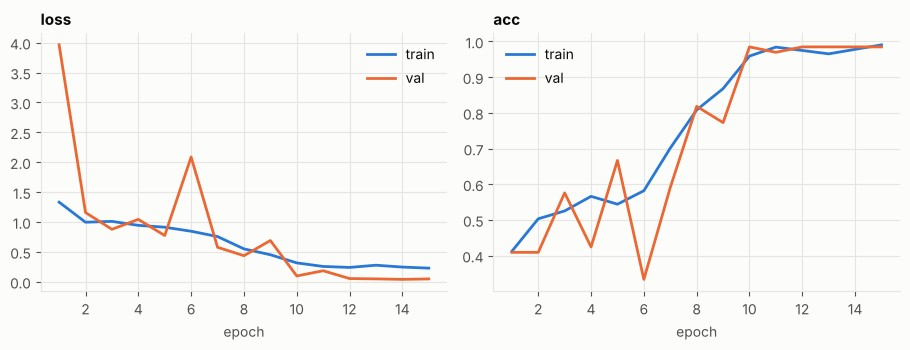

In [6]:
from cvkit.viz import plot_history

_ = plot_history(Path(cfg['output']['dir']) / 'history.csv')

## Evaluate on the test split
Val chose the checkpoint; the **test split** was untouched until now, so it is the honest number. One rule: look at test results, *don't tune on them* — the moment you tweak settings to chase the test score, it stops measuring generalisation.

In [7]:
from tasks.classification.evaluate import evaluate

metrics = evaluate(cfg)

test accuracy: 0.9848 | macro-F1: 0.9848 (66 images)
              precision    recall  f1-score   support

      circle      0.957     1.000     0.978        22
      square      1.000     0.955     0.977        22
    triangle      1.000     1.000     1.000        22

    accuracy                          0.985        66
   macro avg      0.986     0.985     0.985        66
weighted avg      0.986     0.985     0.985        66

reports -> outputs/classification_quick/reports


confusion_matrix.png


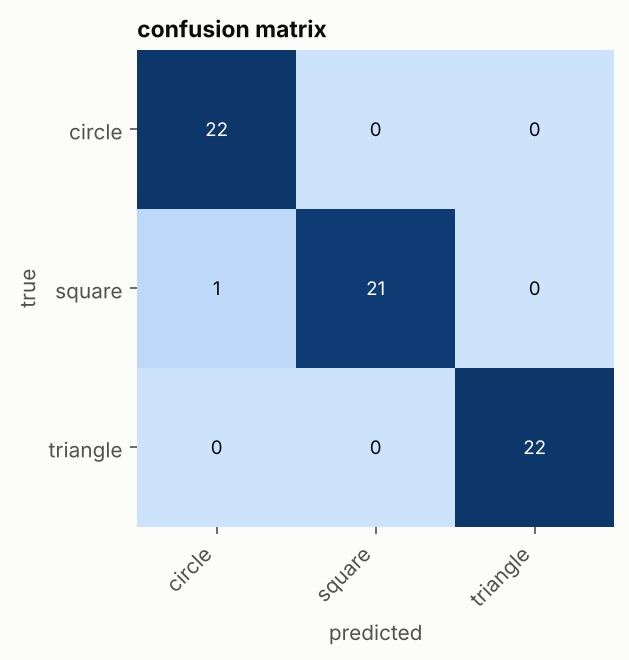

top_losses.png


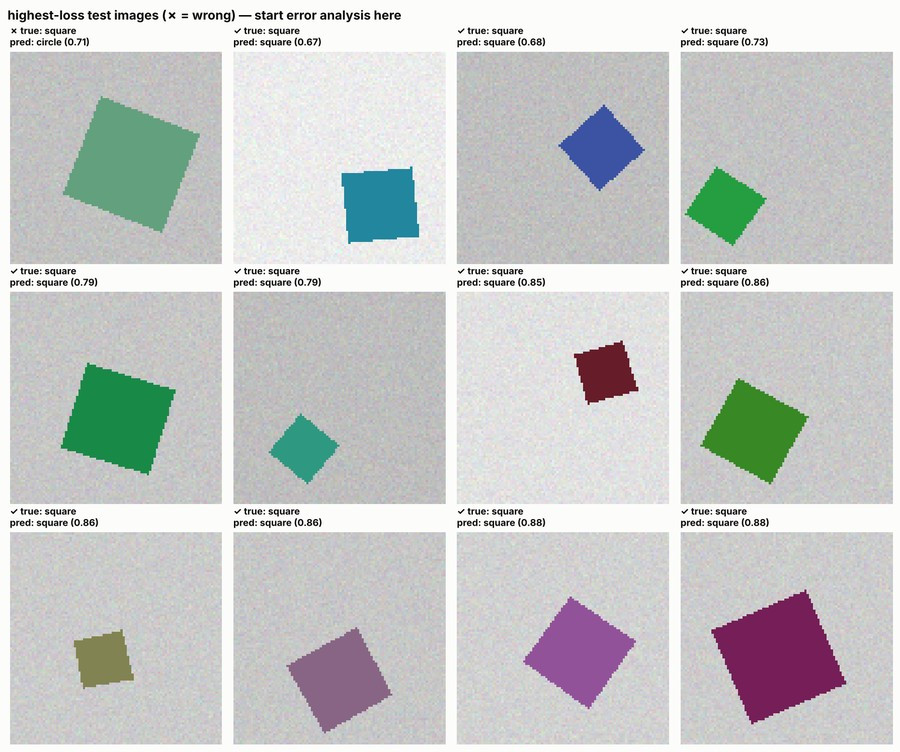

In [8]:
from cvkit.viz import show_image

reports = Path(cfg["output"]["dir"]) / "reports"
for name in ['confusion_matrix.png', 'top_losses.png']:
    print(name)
    show_image(reports / name)

## How to read these results
* **Accuracy** — share of test images labelled correctly. Quote it with the test-set size: on 66 images one mistake is 1.5 points.
* **Per-class precision / recall / F1** (in the printed report) — precision: of what the model *called* class X, how much was X; recall: of what *was* X, how much it found. A class with high precision but low recall is being under-predicted.
* **Macro-F1** — F1 averaged over classes equally; stays honest when classes are imbalanced, where accuracy flatters.
* **Confusion matrix** — find the off-diagonal cells: those are *which* classes get mixed up. Two classes that confuse each other often look alike to a human too, or are labelled inconsistently.
* **Top losses** — the error-analysis step most people skip. For each image ask: is the **label wrong** (fix the data)? is it **genuinely ambiguous** (the ceiling is the labels, not the model)? or is the model **missing something obvious** (more data, targeted augmentation)?

## Experiments worth running
Each one is a one-line change. Re-run the training cell with a different config and compare the best val numbers (change `cfg` like this, then re-run from *Train*):

```python
cfg['model']['arch'] = 'resnet34'     # or any key, same as --set model.arch=resnet34
```

1. `model.freeze_backbone = True` — how far does feature extraction alone get you?
2. `model.arch = 'resnet34'` or `'mobilenet_v3_small'` — does capacity help, or just cost time? how much does a deploy-friendly model give up?
3. `train.epochs` ×2 — is the curve still climbing at the end?
4. `data.augment.rotation = 0` and `data.augment.vflip = False` — what does augmentation buy you on this data?

Change **one thing at a time**, keep the seed, and write down what you changed — otherwise you can't tell what helped.

Next: **[03_predict_and_deploy](03_predict_and_deploy.ipynb)**.